### Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# from matplotlib_inline.backend_inline import set_matplotlib_formats
# set_matplotlib_formats('pdf')

#outputs
os.makedirs("../figures", exist_ok=True)

LABEL_MAP = {
    9: "prefer warmer",
    11: "prefer cooler",  
    10: "no change"
}

# COLOR_MAP = {
#     "prefer warmer": "red",
#     "prefer cooler": "blue",
#     "no change": "green"
# }

COLOR_MAP = {
    "prefer cooler": "#EF6A72",  # muted brick red
    "prefer warmer": "#81AFE4",  # slate/steel blue
    "no change":     "#B0BEC5",  # sage/forest green
}

### Load data

In [2]:
dorn = pd.read_csv("../../data/dorn/DORN_env_phy.csv")
dorn_file_name = "DORN_env_phy.csv"
personai = pd.read_csv("../../data/personai/final_main_dataset_no_missing_ALLENC_with_time_and_hr_age.csv")
personai_file_name = "final_main_dataset_no_missing_ALLENC_with_time_and_hr_age.csv"

datasets = [dorn, personai]

# Map labels
dorn["label"] = dorn["thermal_cozie"].map(LABEL_MAP)
personai["label"] = personai["thermal_cozie"].map(LABEL_MAP)

# Add dataset column
dorn["dataset"] = "DORN"
personai["dataset"] = "PersonAI"

### stacked barchart per dataset

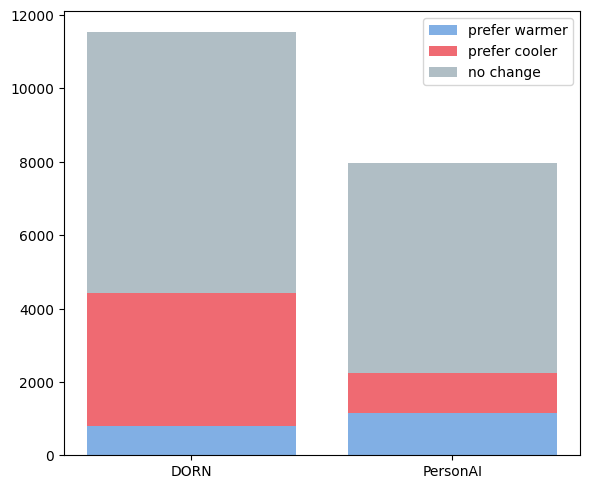

In [3]:
combined = pd.concat([dorn, personai])

dataset_counts = (
    combined.groupby(["dataset", "label"])
    .size()
    .unstack(fill_value=0)
)

dataset_counts = dataset_counts[["prefer warmer", "prefer cooler", "no change"]]
dataset_counts.to_csv("../figures/class_distribution_per_dataset.csv")
bottom = None
plt.figure(figsize=(6,5))

for label in dataset_counts.columns:
    plt.bar(
        dataset_counts.index,
        dataset_counts[label],
        bottom=bottom,
        label=label,
        color=COLOR_MAP[label]
    )
    bottom = dataset_counts[label] if bottom is None else bottom + dataset_counts[label]

#plt.title("Class Distribution per Dataset")
# plt.ylabel("Number of Samples")
plt.legend()
plt.tight_layout()
plt.grid(False)
plt.savefig("../figures/class_distribution_per_dataset.pdf", dpi=300)
# plt.show()


### stacked barchart per person

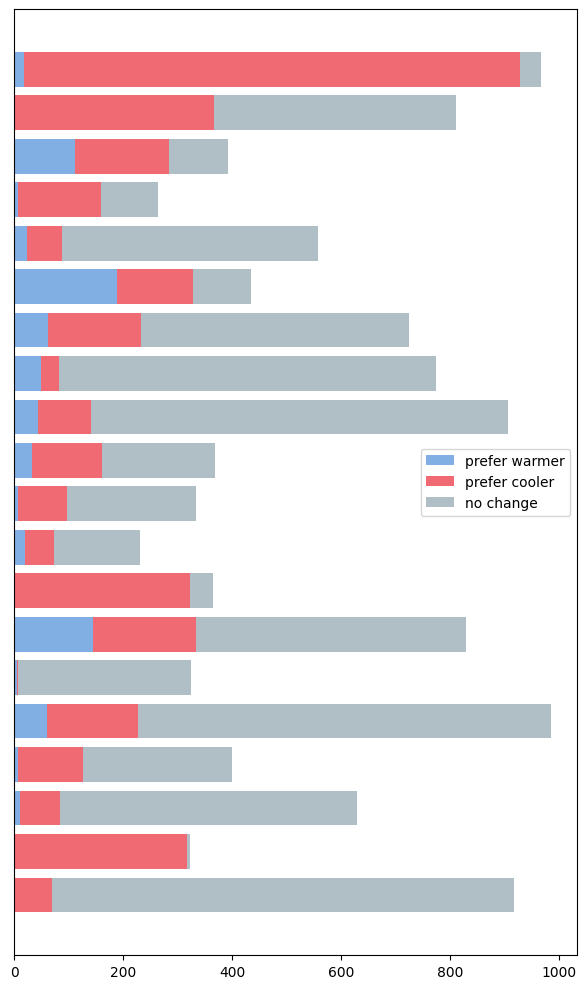

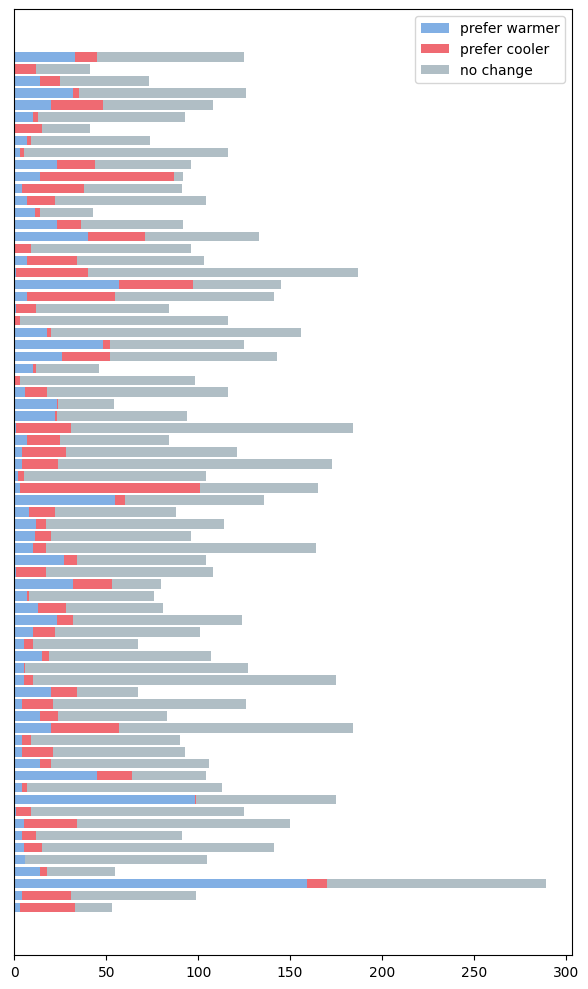

In [4]:
for dataset in datasets:
    person_counts = (
        dataset.groupby(["user_id", "label"])
        .size()
        .unstack(fill_value=0)
    )

    person_counts = person_counts[["prefer warmer", "prefer cooler", "no change"]]

    person_counts.to_csv(f"../figures/{dataset['dataset'].iloc[0]}_class_distribution_per_person.csv")

    bottom = None
    plt.figure(figsize=(6,10))

    for label in person_counts.columns:
        plt.barh(
            person_counts.index,
            person_counts[label],
            left=bottom,
            color=COLOR_MAP[label],
            label=label
        )
        bottom = person_counts[label] if bottom is None else bottom + person_counts[label]

    # plt.xticks(rotation=90)
    plt.yticks([])
    # plt.title(f"{dataset['dataset'].iloc[0]} – Class Distribution per Person")
    # plt.ylabel("Number of Samples")
    plt.legend()
    plt.tight_layout()
    plt.grid(False)
    plt.savefig(f"../figures/{dataset['dataset'].iloc[0]}_class_distribution_per_person.pdf", dpi=300)
    # plt.show()

    person_counts.to_csv(f"../figures/{dataset['dataset'].iloc[0]}_class_distribution_per_person.csv")


In [5]:
# EPV calculation
dorn_pc = (
    dorn.groupby(["user_id", "label"])
    .size()
    .unstack(fill_value=0)
)
print((dorn_pc.min(axis=1)/5).to_markdown())

pers_pc = (
    personai.groupby(["user_id", "label"])
    .size()
    .unstack(fill_value=0)
)
print((dorn_pc.min(axis=1)/5).to_markdown())

# EPV should be above 10


| user_id   |    0 |
|:----------|-----:|
| dorn1     |  0   |
| dorn10    |  0   |
| dorn11    |  2.2 |
| dorn12    |  1.4 |
| dorn13    | 12   |
| dorn14    |  0.4 |
| dorn15    | 28.8 |
| dorn16    |  0   |
| dorn17    |  3.8 |
| dorn18    |  1.2 |
| dorn19    |  6.4 |
| dorn2     |  8.8 |
| dorn20    |  6.8 |
| dorn3     | 12.4 |
| dorn4     | 21.4 |
| dorn5     |  4.8 |
| dorn6     |  1.2 |
| dorn7     | 21.6 |
| dorn8     |  0.2 |
| dorn9     |  3.6 |
| user_id   |    0 |
|:----------|-----:|
| dorn1     |  0   |
| dorn10    |  0   |
| dorn11    |  2.2 |
| dorn12    |  1.4 |
| dorn13    | 12   |
| dorn14    |  0.4 |
| dorn15    | 28.8 |
| dorn16    |  0   |
| dorn17    |  3.8 |
| dorn18    |  1.2 |
| dorn19    |  6.4 |
| dorn2     |  8.8 |
| dorn20    |  6.8 |
| dorn3     | 12.4 |
| dorn4     | 21.4 |
| dorn5     |  4.8 |
| dorn6     |  1.2 |
| dorn7     | 21.6 |
| dorn8     |  0.2 |
| dorn9     |  3.6 |


### DORN Leakage Plot

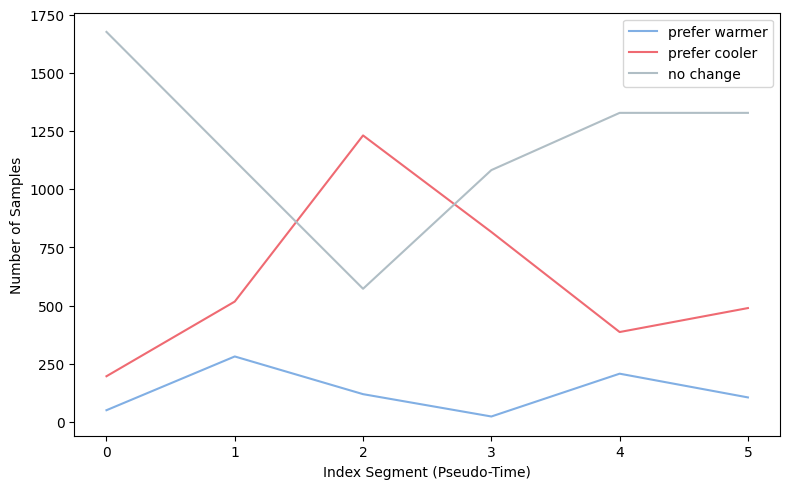

In [6]:
dorn = dorn.sort_values("Unnamed: 0")

#splitting into 6 chunks based on the index
#in their paper they mention the data was collected over a period of 6 months
dorn["index_chunk"] = pd.qcut(
    dorn["Unnamed: 0"],
    q=6,
    labels=False
)

chunk_counts = (
    dorn.groupby(["index_chunk", "label"])
    .size()
    .unstack(fill_value=0)
)

chunk_counts = chunk_counts[["prefer warmer", "prefer cooler", "no change"]]

chunk_counts.to_csv("../figures/DORN_class_distribution_over_time.csv")

plt.figure(figsize=(8,5))

for label in chunk_counts.columns:
    plt.plot(
        chunk_counts.index,
        chunk_counts[label],
        label=label,
        color=COLOR_MAP[label]
    )

#plt.title("DORN – Class Distribution Over Index Segments")
plt.xlabel("Index Segment (Pseudo-Time)")
plt.ylabel("Number of Samples")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.grid(False)
plt.savefig(f"../figures/DORN_class_distribution_over_time.pdf", dpi=300)
plt.show()


### Dataset properties

In [7]:
for dataset in datasets:
    person_counts = (
        dataset.groupby(["user_id", "label"])
        .size()
        .unstack(fill_value=0)
    )
    print(f"Dataset: {dataset['dataset'].iloc[0]}, reference file({dorn_file_name if dataset['dataset'].iloc[0] == 'DORN' else personai_file_name})")
    print(f"Number of participants: {len(person_counts)}")
    print(f"Average samples per participant: {person_counts.sum(axis=1).mean():.2f}")
    print(f"Total samples: {person_counts.sum().sum()}")
    print(f"Balance of classes:")
    for label in person_counts.columns:
        print(f"  {label}: {person_counts[label].sum() * 100/ person_counts.sum().sum():.2f}%")
    print()

Dataset: DORN, reference file(DORN_env_phy.csv)
Number of participants: 20
Average samples per participant: 576.45
Total samples: 11529
Balance of classes:
  no change: 61.66%
  prefer cooler: 31.53%
  prefer warmer: 6.81%

Dataset: PersonAI, reference file(final_main_dataset_no_missing_ALLENC_with_time_and_hr_age.csv)
Number of participants: 72
Average samples per participant: 110.83
Total samples: 7980
Balance of classes:
  no change: 71.85%
  prefer cooler: 13.67%
  prefer warmer: 14.47%

